# Nested models: moments, log p, concentration and entropy
M1 Gaussian (Scat2) ⊂ M2 (L_6 + scalar on the Q=1 Morlet bank; its Db4 variant puts the scalar potentials on the decimated, orthonormal Db4 DWT) ⊂ M3 (+ Q=3 scalar) ⊂ M4 (parked). **To add a model, add one line to `models.py`.**

Run on Jean Zay. Needs `saved_results/` (samples) and the `.npz` of `python nested_models/analyse_nested.py` (via `launch_analysis.sh`).
Convention: p ∝ exp(+θ·φ), so −log p = log Z − θ·φ; log Z is the lower bound H_bound + θ·m_target, so the *width* of −log p is exact and its level carries the moment-matching residual (`gap`).

In [3]:
%matplotlib inline
import sys
from pathlib import Path
NM = Path.cwd() if (Path.cwd() / 'models.py').exists() else Path.cwd() / 'nested_models'
sys.path[:0] = [str(NM), str(NM.parent), str(NM.parent / 'turbulence')]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import logp_entropy as le, plots, stats_extra as se, gaussian_check as gcheck, dwt_marginals as dm
from run_comparison import *
from codes.utils_entropy import data_gaussian_entropy
from models import MODELS, SEEDS
MODELS = {k: MODELS[k] for k in ('M3', 'A constrained windows', 'B A + all masses')}
%matplotlib inline
pd.set_option('display.float_format', '{:.3f}'.format, 'display.width', 250, 'display.max_rows', 100)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [4]:
SEED, THRESHOLD = 900, 1e-8                     # samples and statistics: seed 900; the .npz tables use every available seed
runs, missing = load_runs(MODELS, seed=SEED)
print('not available yet:', missing)
x1 = reference_data(next(iter(runs.values()))['cfg'])
xs = {k: r['xt'] for k, r in runs.items()}
res = le.load_all(MODELS, SEEDS)
H_gauss = float(data_gaussian_entropy(x1))
print({k: tuple(v.shape) for k, v in xs.items()}, tuple(x1.shape), '| seeds in the npz:', {k: len(v) for k, v in res.items()})

not available yet: []
{'M3': (10000, 256), 'A constrained windows': (10000, 256), 'B A + all masses': (10000, 256)} (10000, 256) | seeds in the npz: {'M3': 5, 'A constrained windows': 1, 'B A + all masses': 1}


## 1. Moments

### 1.1 Imposed moments at t = 1
Relative error of the walkers' ⟨φ⟩ against the data moments the SDE was driven to, per potential family (mean over seeds). `# > 10%`: statistics missed by more than 10%.

In [5]:
se.moment_table(res)

N  median   max # > 10%
model                 family                                            
M3                    L_6                        9   0.000 0.000     0.0
                      Scalar_psi_gaussianK     105   0.000 0.302     5.0
                      Scalar_morlet_gaussianK   44   0.000 0.052     0.0
A constrained windows L_6                        9   0.000 0.000     0.0
                      Scalar_psi_gaussianK      98   0.000 0.037     0.0
                      Scalar_morlet_gaussianK   43   0.000 0.017     0.0
B A + all masses      L_6                        9   0.000 0.000     0.0
                      Scalar_psi_gaussianK     132   0.000 0.037     0.0
                      Scalar_morlet_gaussianK   60   0.000 0.016     0.0

### 1.2 Out-of-model statistics, generated / data (1 = perfect)
Scat2 is imposed by M1 only, L_6 by M2 and M3 only: for the other models these rows are a pure check.

In [6]:
se.fixed_stats_table(x1, xs, J=8)

,M3,A constrained windows,B A + all masses
L_6[0],1.000,1.000,1.000
L_6[1],1.000,1.000,1.000
L_6[2],1.000,1.000,1.000
L_6[3],1.000,1.000,1.000
L_6[4],1.000,1.000,1.000
L_6[5],1.000,1.000,1.000
L_6[6],1.000,1.000,1.000
L_6[7],1.000,1.000,1.000
L_6[8],1.000,1.000,1.000
Scat2[0],0.762,0.782,0.848


### 1.3 Marginals of the wavelet coefficients, generated / data
Q=1 bank (imposed by the scalar potentials of M2/M3), then the Q=3 bank (not imposed by M2). Rows: j0 = finest.

In [7]:
N = len(x1)
for bank in ('morlet', 'psi'):
    print(f'Re(x * psi), Q={BANKS[bank]}'); display(channel_table(x1, xs, bank=bank, J=8, n_series=N))

Re(x * psi), Q=1


m2                                           m4                                           m6                                        q0.99                                        q0.999                                        q0.9999  \
        M3 A constrained windows B A + all masses    M3 A constrained windows B A + all masses    M3 A constrained windows B A + all masses    M3 A constrained windows B A + all masses     M3 A constrained windows B A + all masses      M3   
j0q0 0.751                 0.771            0.839 0.416                 0.406            0.451 0.994                 0.993            0.998 1.025                 1.005            1.001  0.891                 0.901            0.975   0.644   
j1q0 0.781                 0.806            0.895 0.367                 0.373            0.499 0.576                 0.577            0.588 1.031                 1.019            1.002  0.885                 0.901            0.976   0.661   
j2q0 0.877                 0.887            0.974 0.601                 0.620            0.831 0.751                 0.749            0.822 1.029                 1.029            1.000  0.894                 0.901            0.988   0.772   
j3q0 0.947                 0.950            0.997 0.807                 0.821            0.975 0.963                 0.965            0.981 1.025                 1.023            1.001  0.921                 0.929            0.990   0.838   
j4q0 1.001                 1.001            0.999 0.987                 0.988            0.997 1.002                 1.002            1.011 1.003                 1.003            1.001  0.978                 0.979            0.991   0.994   
j5q0 1.001                 1.001            1.000 1.004                 1.004            1.003 1.010                 1.010            1.012 0.999                 0.999            1.000  1.006                 1.007            1.001   1.008   
j6q0 1.000                 1.000            1.000 0.999                 0.999            0.999 1.000                 1.000            0.999 1.002                 1.002            1.000  0.999                 0.999            1.004   1.014   
j7q0 1.000                 1.000            1.000 0.999                 0.999            1.000 1.000                 1.000            1.000 1.001                 1.001            1.000  0.994                 0.994            1.001   1.019   

                                             
     A constrained windows B A + all masses  
j0q0                 0.667            0.788  
j1q0                 0.687            0.827  
j2q0                 0.781            0.917  
j3q0                 0.848            0.992  
j4q0                 0.993            1.008  
j5q0                 1.008            1.012  
j6q0                 1.015            1.008  
j7q0                 1.019            1.010

Re(x * psi), Q=3


m2                                           m4                                           m6                                        q0.99                                        q0.999                                        q0.9999  \
        M3 A constrained windows B A + all masses    M3 A constrained windows B A + all masses    M3 A constrained windows B A + all masses    M3 A constrained windows B A + all masses     M3 A constrained windows B A + all masses      M3   
j0q0 0.975                 0.935            0.835 0.208                 3.034            0.773 0.122                 9.083            1.598 1.011                 1.039            1.043  0.997                 0.894            0.886   0.871   
j0q1 0.774                 0.660            0.625 0.673                 0.563            0.350 1.022                 0.848            0.513 1.012                 1.056            1.057  0.957                 0.849            0.850   0.630   
j0q2 0.613                 0.547            0.473 0.399                 0.334            0.103 0.503                 0.361            0.072 1.019                 1.052            1.059  0.913                 0.832            0.818   0.531   
j1q0 0.483                 0.578            0.522 0.083                 0.117            0.085 0.039                 0.066            0.044 1.018                 0.989            1.004  0.882                 1.014            0.918   0.489   
j1q1 0.528                 0.618            0.697 0.101                 0.118            0.193 0.050                 0.056            0.111 1.023                 1.003            0.998  0.846                 0.966            1.000   0.520   
j1q2 0.604                 0.652            0.773 0.145                 0.160            0.225 0.076                 0.074            0.065 1.026                 1.015            0.999  0.854                 0.908            1.012   0.537   
j2q0 0.711                 0.729            0.870 0.178                 0.190            0.349 0.048                 0.049            0.100 1.023                 1.020            1.000  0.849                 0.875            0.998   0.634   
j2q1 0.879                 0.888            0.990 0.693                 0.698            0.912 0.958                 0.974            0.935 1.020                 1.016            1.002  0.907                 0.921            1.014   0.823   
j2q2 0.870                 0.887            0.997 0.885                 0.903            1.033 1.930                 1.904            1.553 1.026                 1.022            0.999  0.933                 0.948            1.017   0.843   
j3q0 0.901                 0.898            0.995 0.801                 0.802            0.958 0.762                 0.742            0.939 1.018                 1.014            0.998  0.956                 0.961            0.988   0.865   
j3q1 0.928                 0.934            1.002 0.848                 0.848            1.016 0.648                 0.646            1.035 1.014                 1.013            0.998  0.962                 0.959            0.986   0.916   
j3q2 0.982                 0.986            0.991 0.886                 0.885            0.918 0.636                 0.626            0.704 1.008                 1.005            1.003  0.975                 0.979            0.986   0.924   
j4q0 1.001                 1.000            1.000 1.029                 1.028            1.022 1.181                 1.180            1.150 1.001                 1.000            1.001  0.987                 0.988            0.990   1.043   
j4q1 1.010                 1.010            1.000 1.038                 1.038            1.016 1.105                 1.102            1.061 0.996                 0.997            1.001  1.007                 1.007            0.987   1.042   
j4q2 1.003                 1.003            1.001 1.008                 1.008            1.024 1.026                 1.022            1.

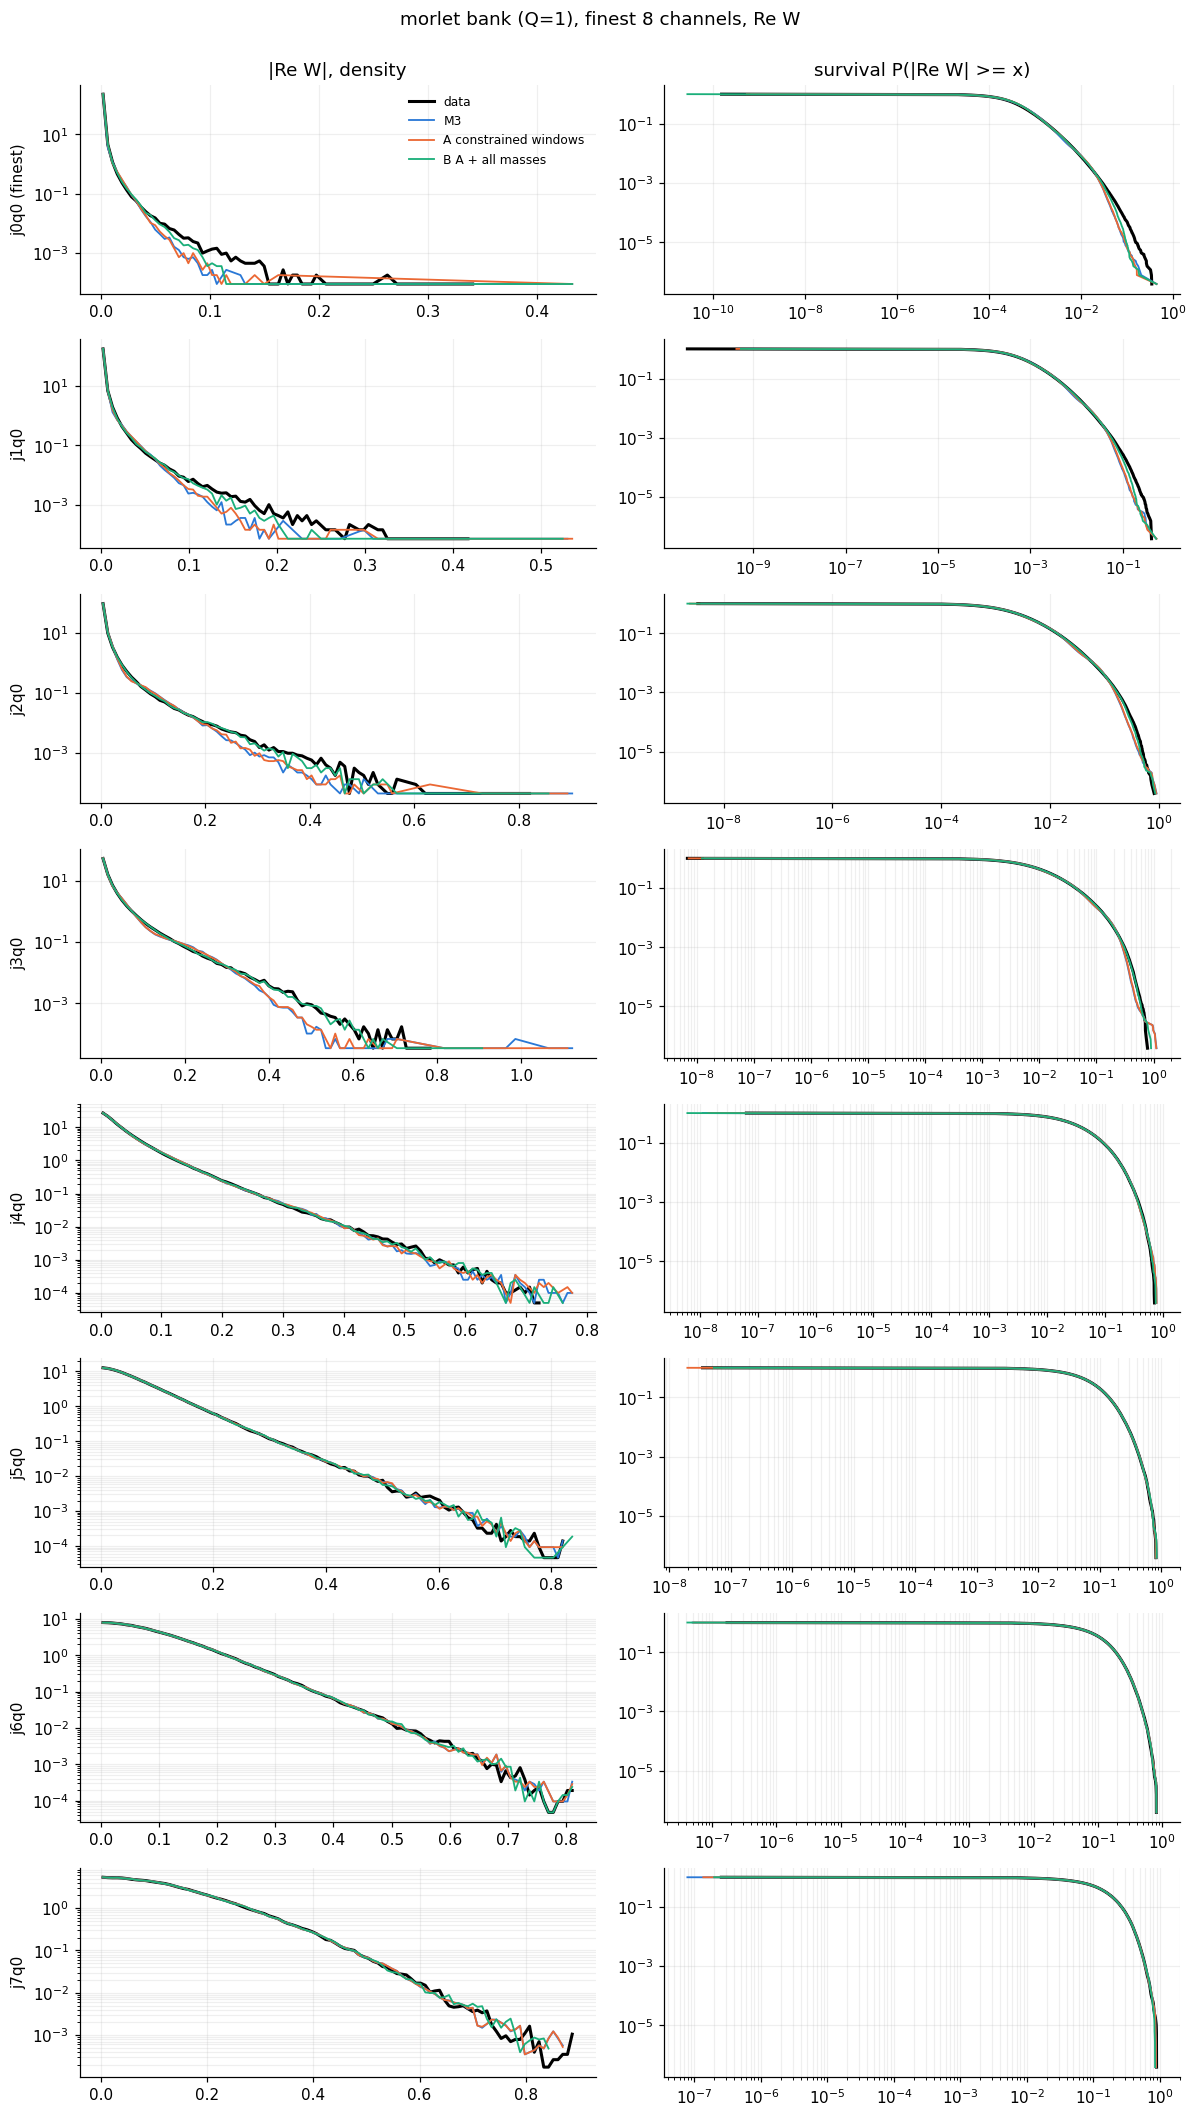

In [8]:
plot_tail_hists(x1, xs, bank='morlet', n_ch=8, n_series=N)

Modulus |x ⋆ ψ| (not imposed by any scalar potential), Q=1 bank:

In [9]:
se.modulus_table(x1, xs, bank='morlet', J=8)

,m2,m4,m6,q0.99,q0.999,q0.9999,m2,m4,m6,q0.99,q0.999,q0.9999,m2,m4,m6,q0.99,q0.999,q0.9999
,M3,M3,M3,M3,M3,M3,A constrained windows,A constrained windows,A constrained windows,A constrained windows,A constrained windows,A constrained windows,B A + all masses,B A + all masses,B A + all masses,B A + all masses,B A + all masses,B A + all masses
j0q0,0.920,0.453,0.310,1.098,0.949,0.741,0.966,0.494,0.318,1.082,0.979,0.756,1.036,0.635,0.392,1.061,1.081,0.828
j1q0,0.981,0.662,0.562,1.104,0.894,0.863,1.007,0.742,0.702,1.110,0.931,0.831,1.076,1.009,1.026,1.075,1.034,0.920
j2q0,1.023,0.913,0.914,1.145,0.910,0.975,1.039,0.983,1.050,1.141,0.936,0.989,1.119,1.293,1.459,1.094,1.049,1.068
j3q0,1.025,0.887,0.592,1.102,0.929,0.862,1.025,0.903,0.627,1.089,0.933,0.861,1.070,1.122,1.050,1.056,1.028,0.988
j4q0,1.057,1.044,0.940,1.046,0.963,0.974,1.057,1.048,0.955,1.046,0.976,0.980,1.055,1.071,1.011,1.042,1.000,1.000
j5q0,1.011,0.923,0.728,0.976,0.921,0.851,1.011,0.923,0.728,0.976,0.921,0.852,1.011,0.930,0.743,0.978,0.923,0.875
j6q0,1.005,0.984,0.991,0.968,1.007,1.029,1.005,0.985,0.992,0.969,1.008,1.029,1.006,0.977,0.959,0.967,1.009,1.000
j7q0,0.972,0.955,0.880,0.994,0.918,0.832,0.972,0.955,0.880,0.994,0.919,0.832,0.972,0.950,0.869,0.981,0.917,0.881


Per-sample mean (k = 0 mode) and the ℓ1/ℓ2 ratio per scale (lower = sparser):

,std,excess kurtosis,q0.001,q0.999,std / data
data,0.905,0.080,-2.593,2.899,1.000
M3,0.904,0.079,-2.827,2.585,0.999
A constrained windows,0.904,0.079,-2.827,2.585,0.999
B A + all masses,0.904,0.067,-2.821,2.625,1.000


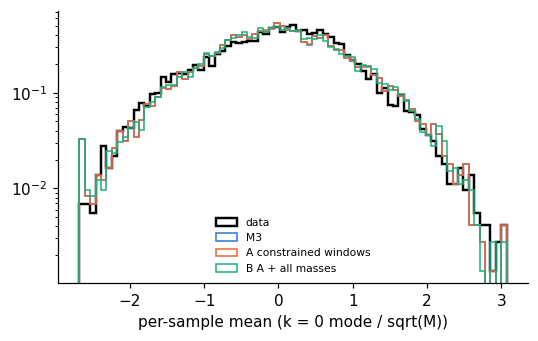

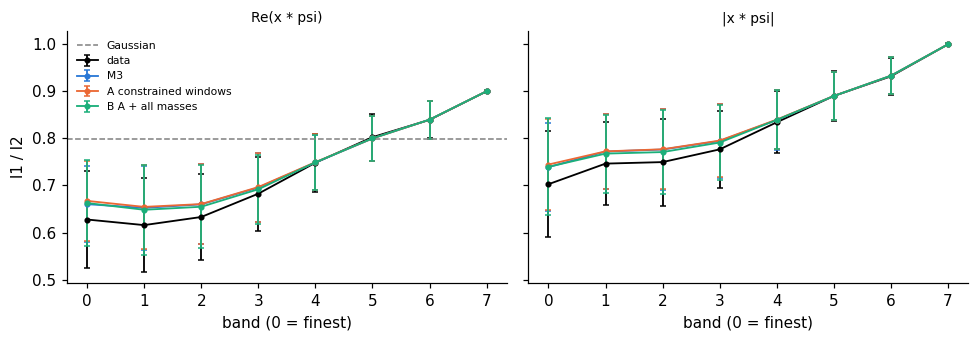

In [10]:
display(se.k0_summary(x1, xs)); se.plot_k0(x1, xs); se.plot_l1l2(x1, xs);

Coefficients of the decimated Db4 DWT per scale (the marginals the Db4 arm imposes; last row = approximation block):

In [11]:
for name, t in dm.dwt_scale_table(x1, xs, order=4, J=8).items():
    print(name); display(t)

M3


,N per series,m2,m4,m6,q0.99,q0.999,q0.9999
j0,128,0.612,0.147,0.115,1.108,0.898,0.530
j1,64,0.728,0.170,0.057,1.021,0.882,0.624
j2,32,0.896,0.708,0.650,1.019,0.908,0.844
j3,16,0.982,0.925,0.816,1.017,0.979,0.887
j4,8,0.997,1.010,1.151,0.987,0.977,0.997
j5,4,0.996,0.971,0.921,0.996,1.008,0.964
j6,2,0.977,0.956,0.980,1.001,0.939,1.124
j7,1,1.033,1.075,1.125,1.013,0.991,1.102
approx,1,0.997,0.994,1.000,0.988,0.974,0.986


A constrained windows


,N per series,m2,m4,m6,q0.99,q0.999,q0.9999
j0,128,0.640,0.091,0.050,1.138,0.946,0.602
j1,64,0.758,0.180,0.049,1.020,0.902,0.651
j2,32,0.905,0.733,0.691,1.019,0.917,0.841
j3,16,0.984,0.935,0.833,1.013,0.985,0.911
j4,8,0.997,1.008,1.139,0.987,0.981,0.994
j5,4,0.996,0.971,0.921,0.995,1.009,0.962
j6,2,0.978,0.956,0.980,1.001,0.943,1.125
j7,1,1.033,1.075,1.125,1.013,0.991,1.102
approx,1,0.997,0.994,1.000,0.988,0.974,0.986


B A + all masses


,N per series,m2,m4,m6,q0.99,q0.999,q0.9999
j0,128,0.696,0.242,0.367,1.108,0.980,0.702
j1,64,0.839,0.262,0.059,1.014,0.953,0.755
j2,32,0.997,1.002,1.181,1.001,0.977,0.982
j3,16,1.010,1.062,1.066,1.002,1.024,1.041
j4,8,0.994,1.024,1.211,0.997,0.992,1.071
j5,4,0.995,0.966,0.904,0.983,0.998,0.960
j6,2,0.978,0.958,0.985,1.001,0.939,1.137
j7,1,1.033,1.069,1.082,1.011,1.012,1.104
approx,1,0.999,0.994,1.000,0.989,0.961,1.044


## 2. log p, concentration and entropy

### 2.1 Summary
`negentropy = H_gauss − H_bound`, with H_gauss the entropy of the Gaussian that has the data covariance. `gap = θ·(m_target − ⟨φ⟩)` = `H_sample − H_bound`. Mean ± std over seeds.

In [12]:
le.summary_table(res, H_gauss=H_gauss)

,seeds,H_bound,H_gauss (data),negentropy H_gauss - H_bound,H_sample (mean -log p),gap = theta.(m_target - <phi>),std(-log p) model,std / H,cross-entropy (data),std(-log p) data
model,,,,,,,,,,
M3,5,-1074.73 ± 0.24,-911.83,162.91 ± 0.24,-1070.84 ± 0.23,3.89 ± 0.04,115.52 ± 0.50,0.11 ± 0.00,-1076.61 ± 0.24,135.92 ± 0.05
A constrained windows,1,-1053.21 ± 0.00,-911.83,141.38 ± 0.00,-1049.79 ± 0.00,3.42 ± 0.00,103.21 ± 0.00,0.10 ± 0.00,-1054.80 ± 0.00,129.52 ± 0.00
B A + all masses,1,-1048.00 ± 0.00,-911.83,136.17 ± 0.00,-1044.70 ± 0.00,3.30 ± 0.00,104.89 ± 0.00,0.10 ± 0.00,-1049.59 ± 0.00,128.84 ± 0.00


### 2.2 −log p on model samples (filled) and on data (line)
Centred on the model mean. The cross-entropy (data mean) is in the table above. The M1 panel shows the exact χ²_d prediction.

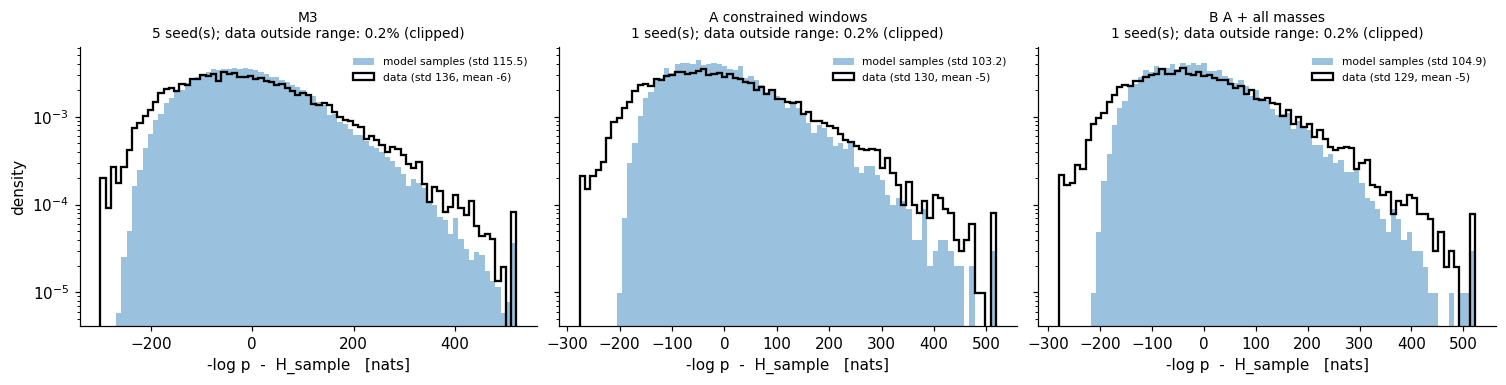

In [13]:
plots.plot_nlogp(res);

### 2.3 Concentration and reproducibility across seeds

,seeds,Pearson mean,Pearson min,Spearman mean,Spearman min
model,,,,,
M3,5,1.000,1.000,1.000,1.000


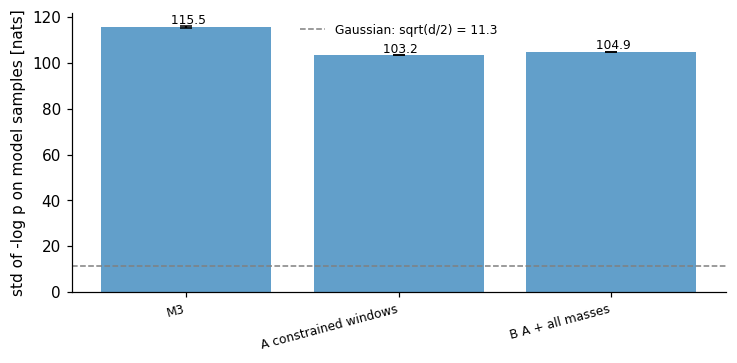

In [14]:
plots.plot_concentration(res); display(plots.seed_agreement(res))

### 2.4 Entropy bound along the transport (dashed: Gaussian with the data covariance)

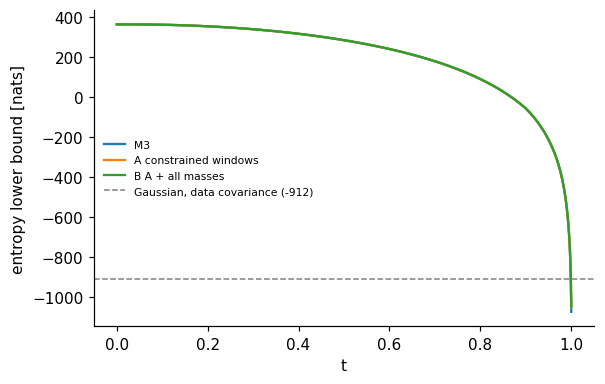

In [15]:
plots.plot_entropy_evolution(runs, H_gauss, d=x1.shape[-1]);

### 2.5 Which potential family and which scale contribute to log p
A split is ill-defined when two families cancel (strong negative correlation with a std far above the total's).

,std(total),ill-defined splits
model,,
M3,115.722,Scalar_psi_gaussianK vs Scalar_morlet_gaussian...
A constrained windows,103.202,Scalar_psi_gaussianK vs Scalar_morlet_gaussian...
B A + all masses,104.887,none


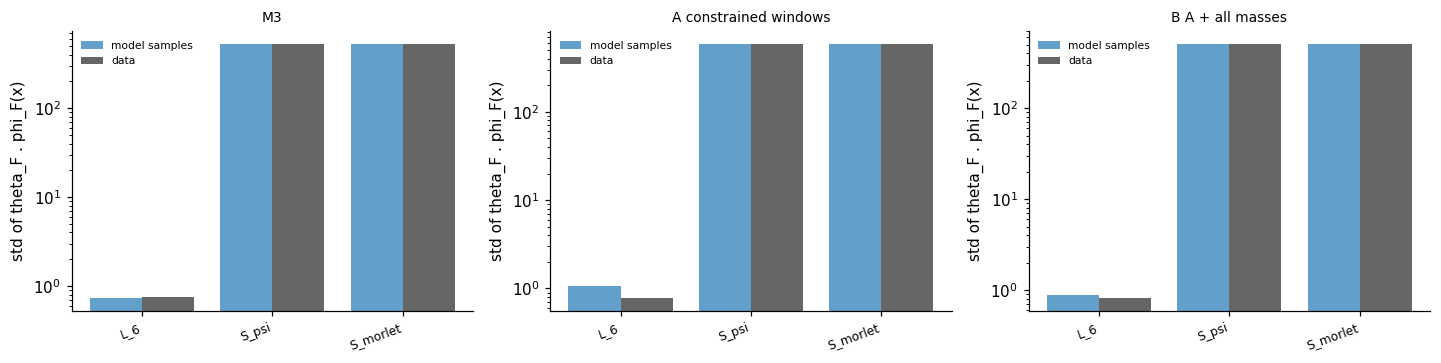

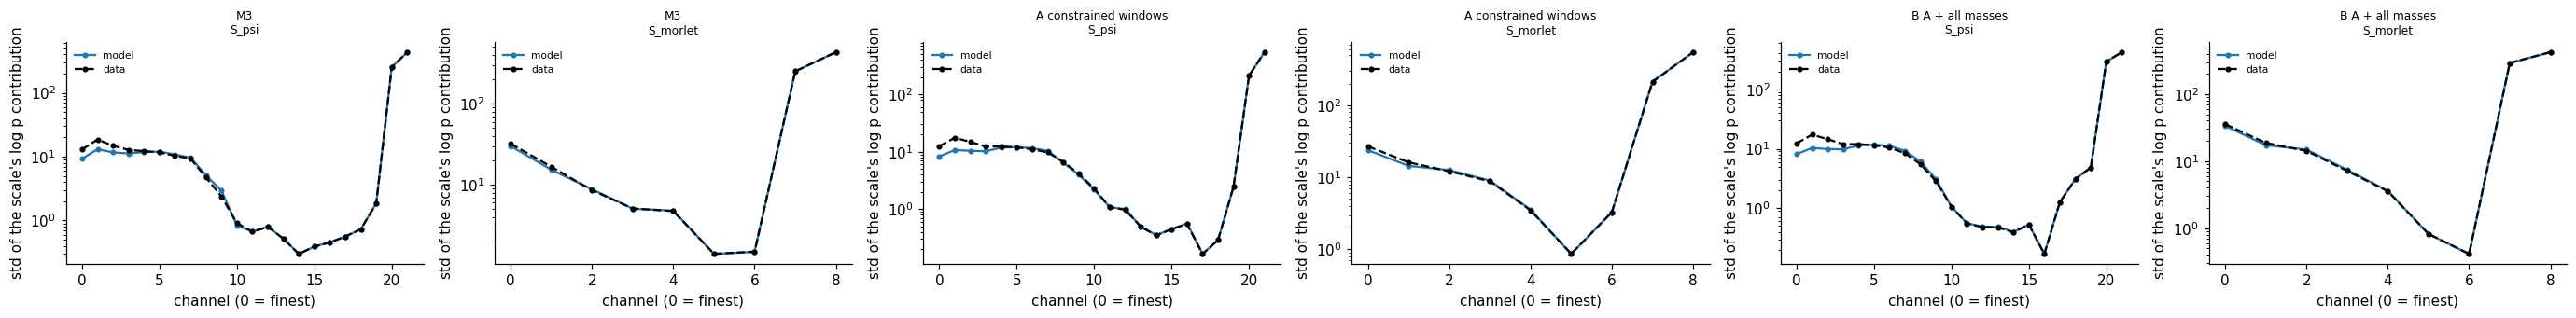

In [16]:
plots.plot_families(res); plots.plot_per_scale(res); display(plots.split_flags(res))

### 2.6 Signs of θ (confinement)
θ < 0 is needed on L_6 and on the outer region (reg3) of each scalar channel. 'Possibly unconfined': both positive on the same channel.

In [17]:
plots.sign_table(res)

,seeds,theta_L6 > 0,theta_outer(reg3) > 0,channels both > 0 (possibly unconfined),Scat2 bands theta > 0
model,,,,,
M3,5,22 / 45,49 / 110,12,-
A constrained windows,1,5 / 9,12 / 22,3,-
B A + all masses,1,5 / 9,10 / 22,2,-


### 2.7 M1 check against the exact Gaussian
For Scat2 the fitted model is an exact circulant Gaussian: exact H and log Z, existence (g(ω) < 0 everywhere) and the χ²_d test of −log p on its own samples (`var(y)/2d` → 1).

In [18]:
g = [n for n in res if 'Gaussian' in n and res[n]]
gcheck.validation_table(res[g[0]]) if g else 'no Gaussian model in the registry'

'no Gaussian model in the registry'

## 3. Samples across −log p
Top row of each model: its samples at quantiles of −log p (0 = most likely, 1 = rarest); below each, the data signal with the closest −log p. Pool: the 10 000 final walkers of seed 900.

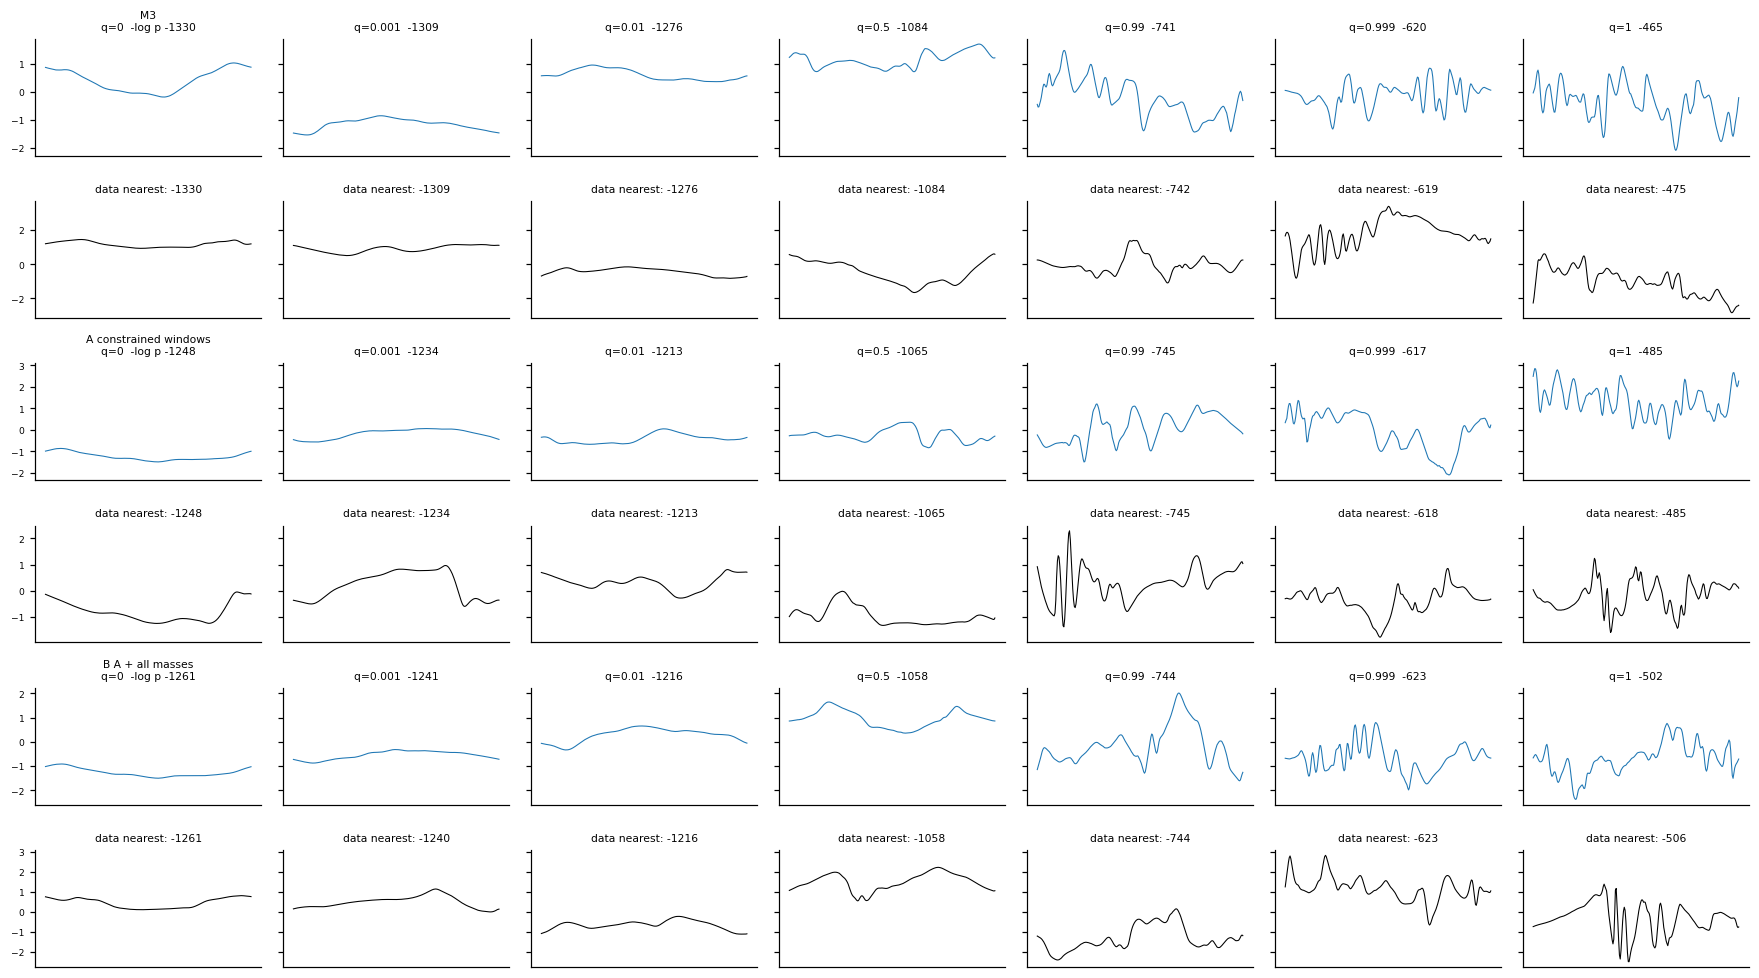

In [19]:
se.plot_gallery(res, xs, x1, seed=SEED);

## Context: physical statistics

,reg,sched,n_terms,nt,n1,runtime_h,mm_final_median,mm_final_p90,mm_final_max,mm_n_above_1pct,S2_ratio_tau1,flat4_ratio_tau1,flat6_ratio_tau1,skew_tau1 (data 0.018),spec_logrms,spec_logrms_oct,wav_E_logrms,wav_flat_logrms,marg_KS,wav_KS_max
M3,0.000,2.000,3.000,55000.000,10000.000,NaN,0.000,0.004,0.246,10.000,0.934,0.855,3.022,0.084,0.419,0.318,0.304,0.614,0.015,0.086
A constrained windows,0.000,2.000,3.000,55000.000,10000.000,4.000,0.000,0.000,0.014,1.000,0.940,0.874,3.059,0.097,0.408,0.288,0.279,0.598,0.015,0.093
B A + all masses,0.000,2.000,3.000,55000.000,10000.000,4.600,0.000,0.000,0.014,1.000,0.981,0.929,2.102,0.085,0.446,0.299,0.284,0.508,0.015,0.094


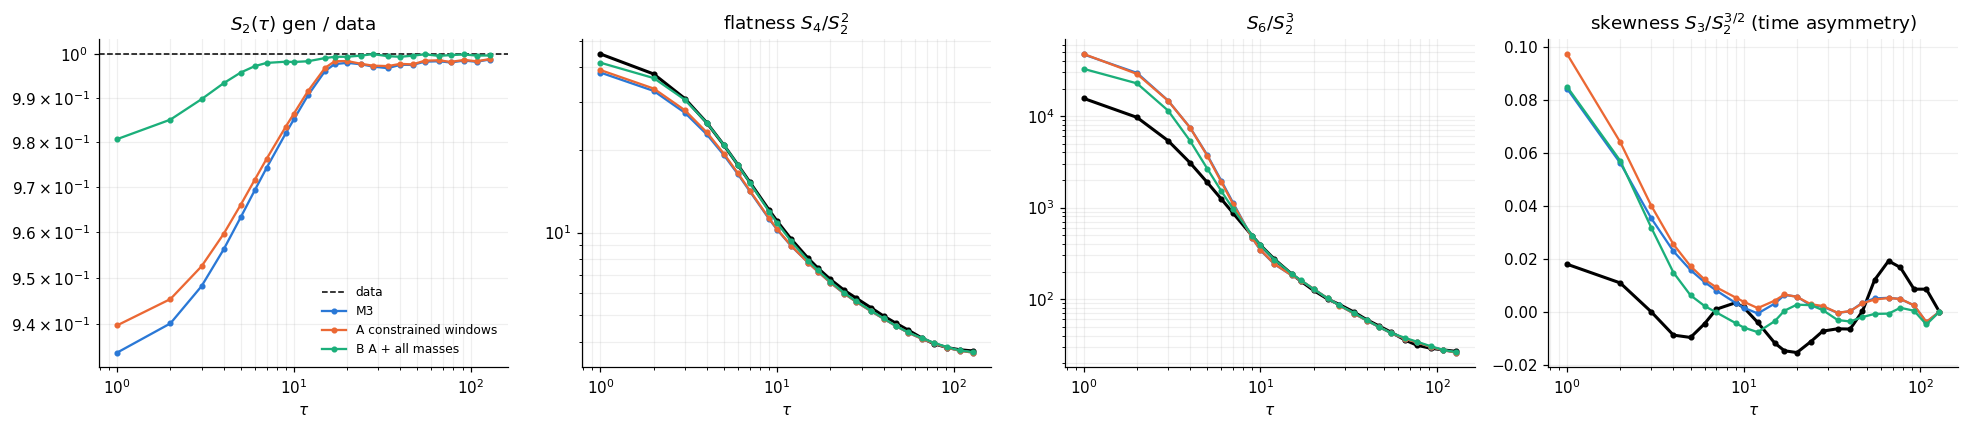

In [20]:
S_ref = compute_stats(x1); S_runs = {k: compute_stats(v) for k, v in xs.items()}
display(summary_table(S_ref, S_runs, runs, THRESHOLD, ks=wavelet_ks(S_ref, S_runs)))
plot_structure(S_ref, S_runs)